Saving heart_failure_clinical_records_dataset.csv to heart_failure_clinical_records_dataset.csv
Dataset Loaded Successfully!

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7  

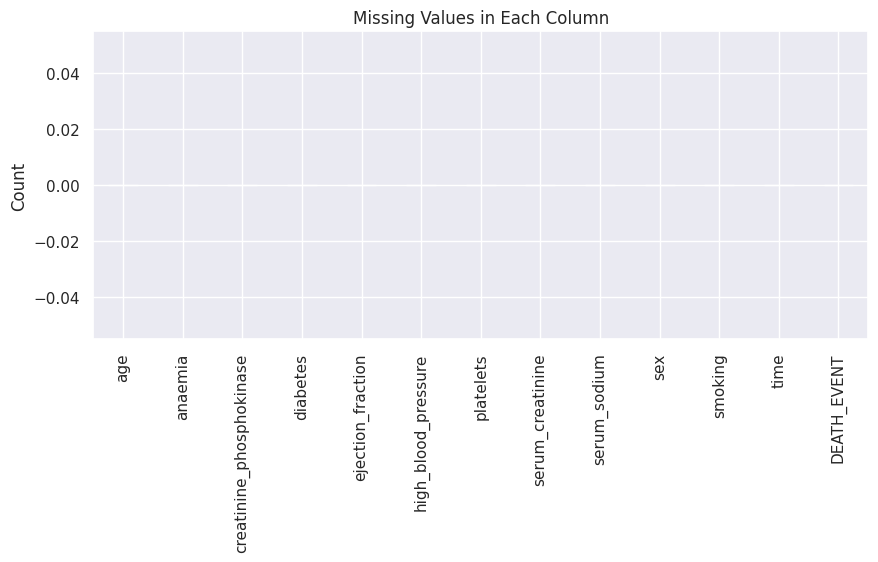

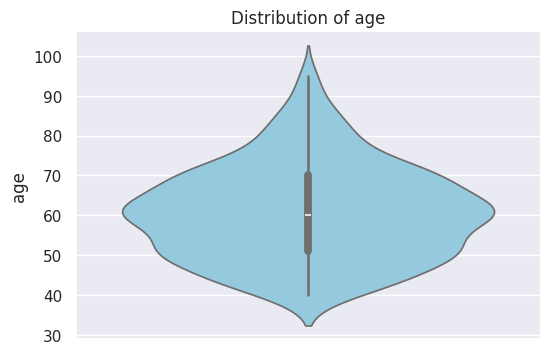

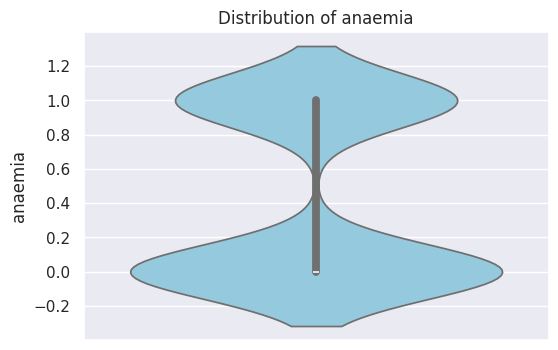

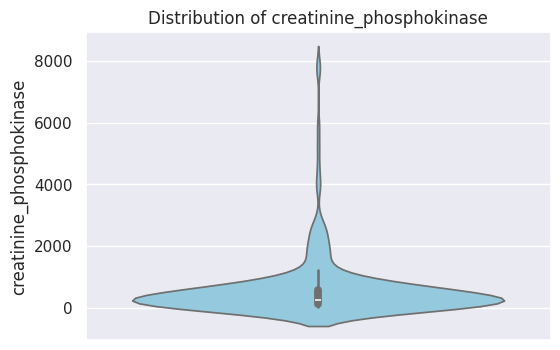

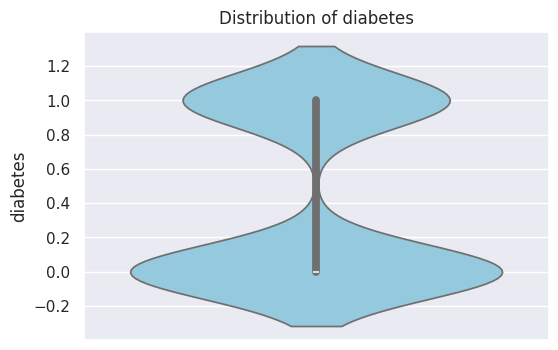

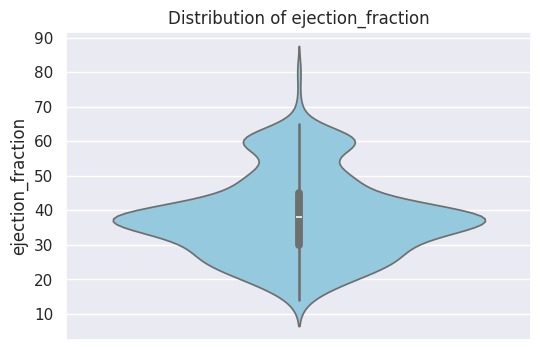

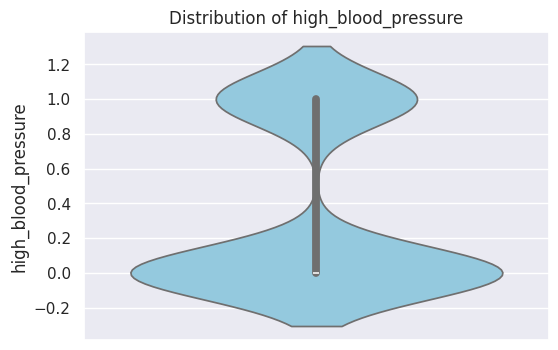

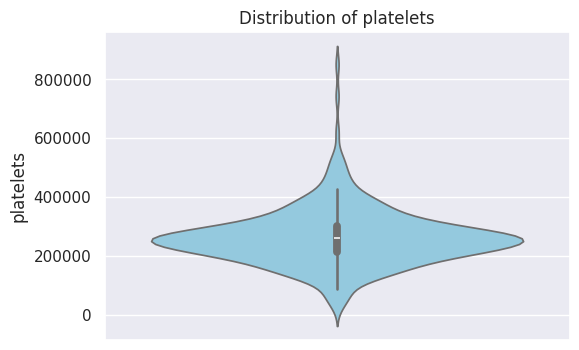

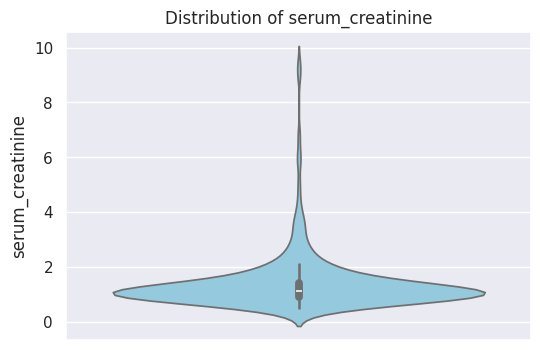

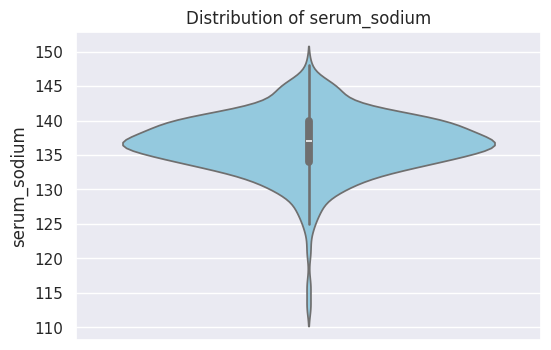

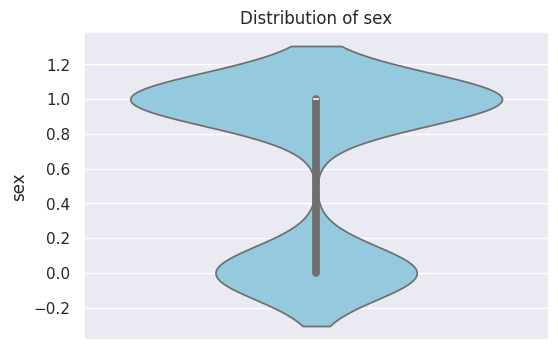

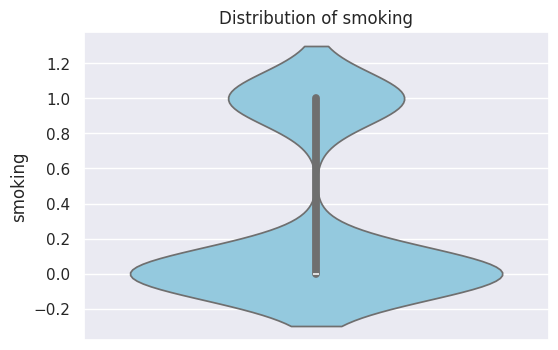

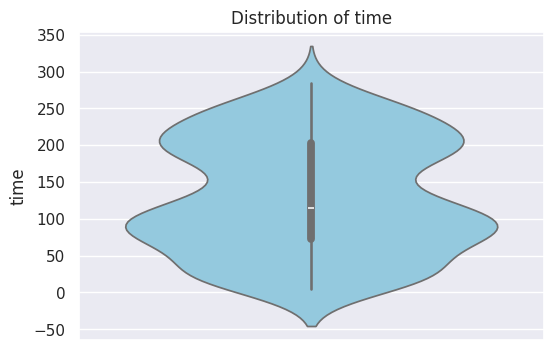

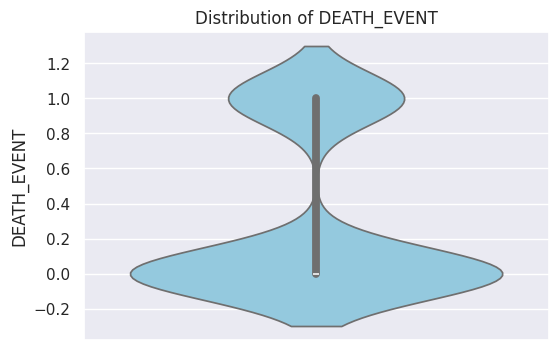


Summary Statistics BEFORE Cleaning
              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                 23.000000    0.000000   
25%     51.000000    0.000000                116.500000    0.000000   
50%     60.000000    0.000000                250.000000    0.000000   
75%     70.000000    1.000000                582.000000    1.000000   
max     95.000000    1.000000               7861.000000    1.000000   

       ejection_fraction  high_blood_pressure      platelets  \
count         299.000000           299.000000     299.000000   
mean           38.083612             0.351171  263358.029264   
std            11.834841             0.478136   97804.236869   
min            14.000000             0.000000   25100.000000   
25% 

/tmp/ipykernel_1668/1755462024.py:91: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


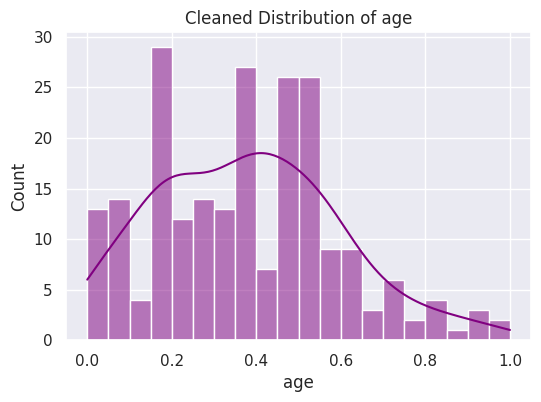

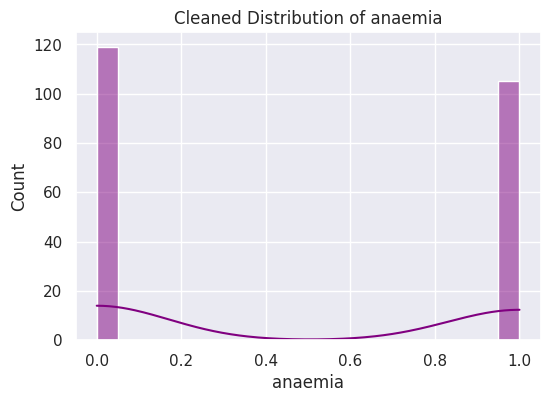

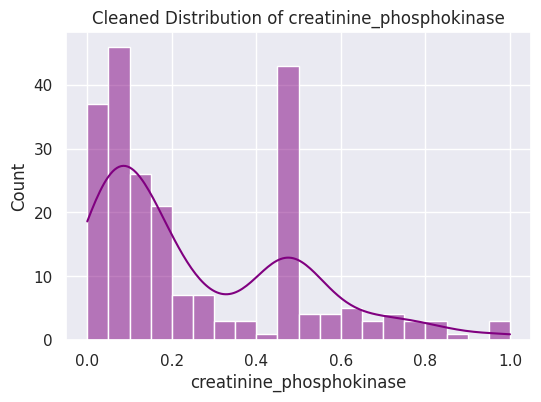

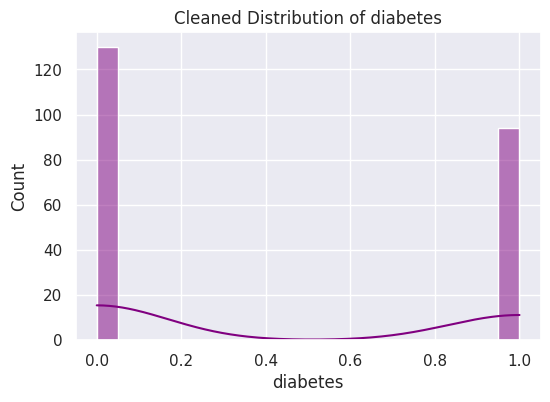

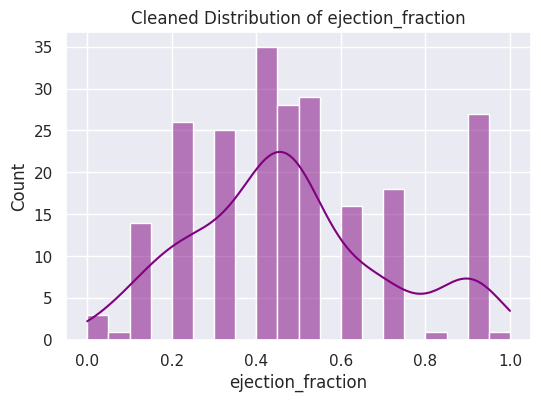

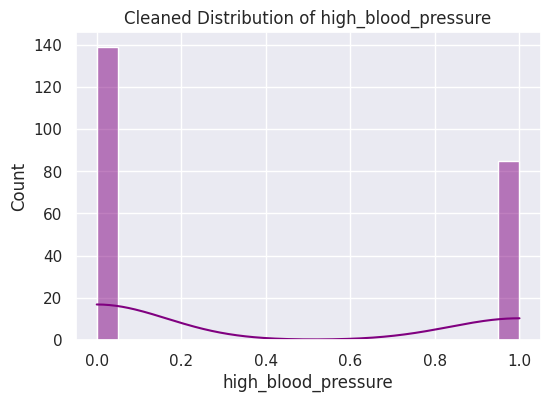

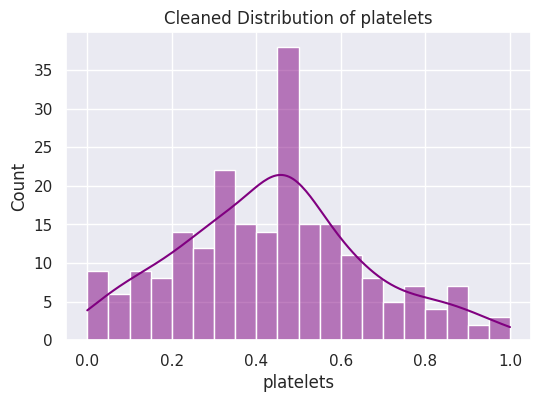

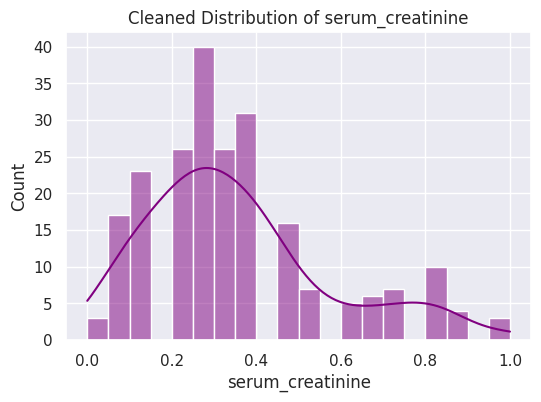

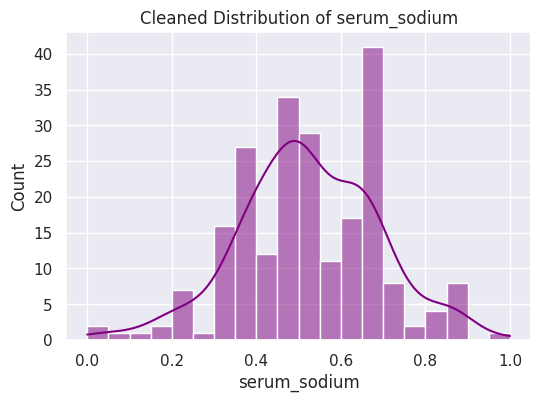

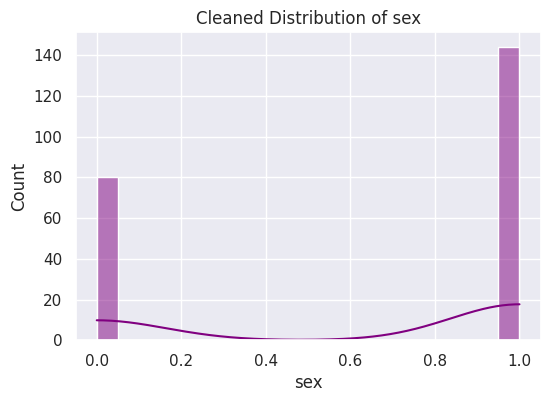

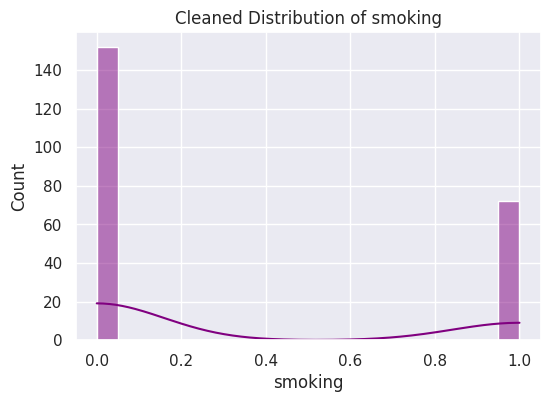

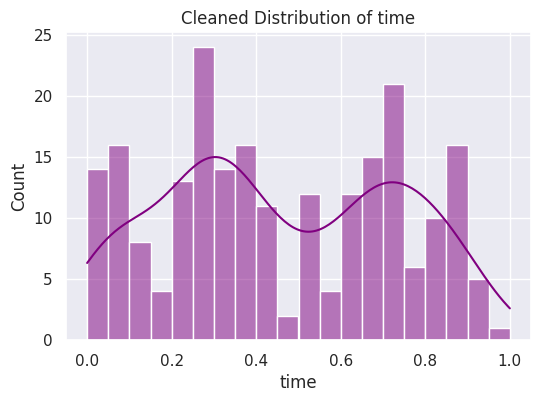

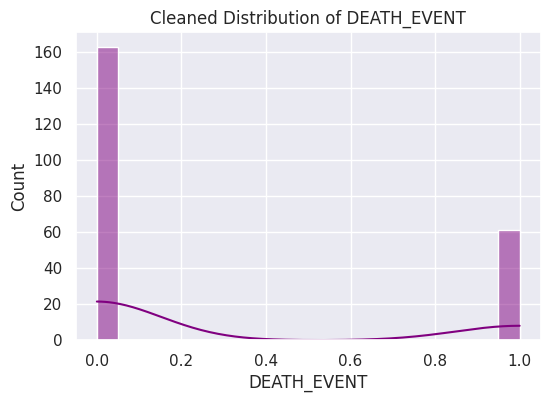

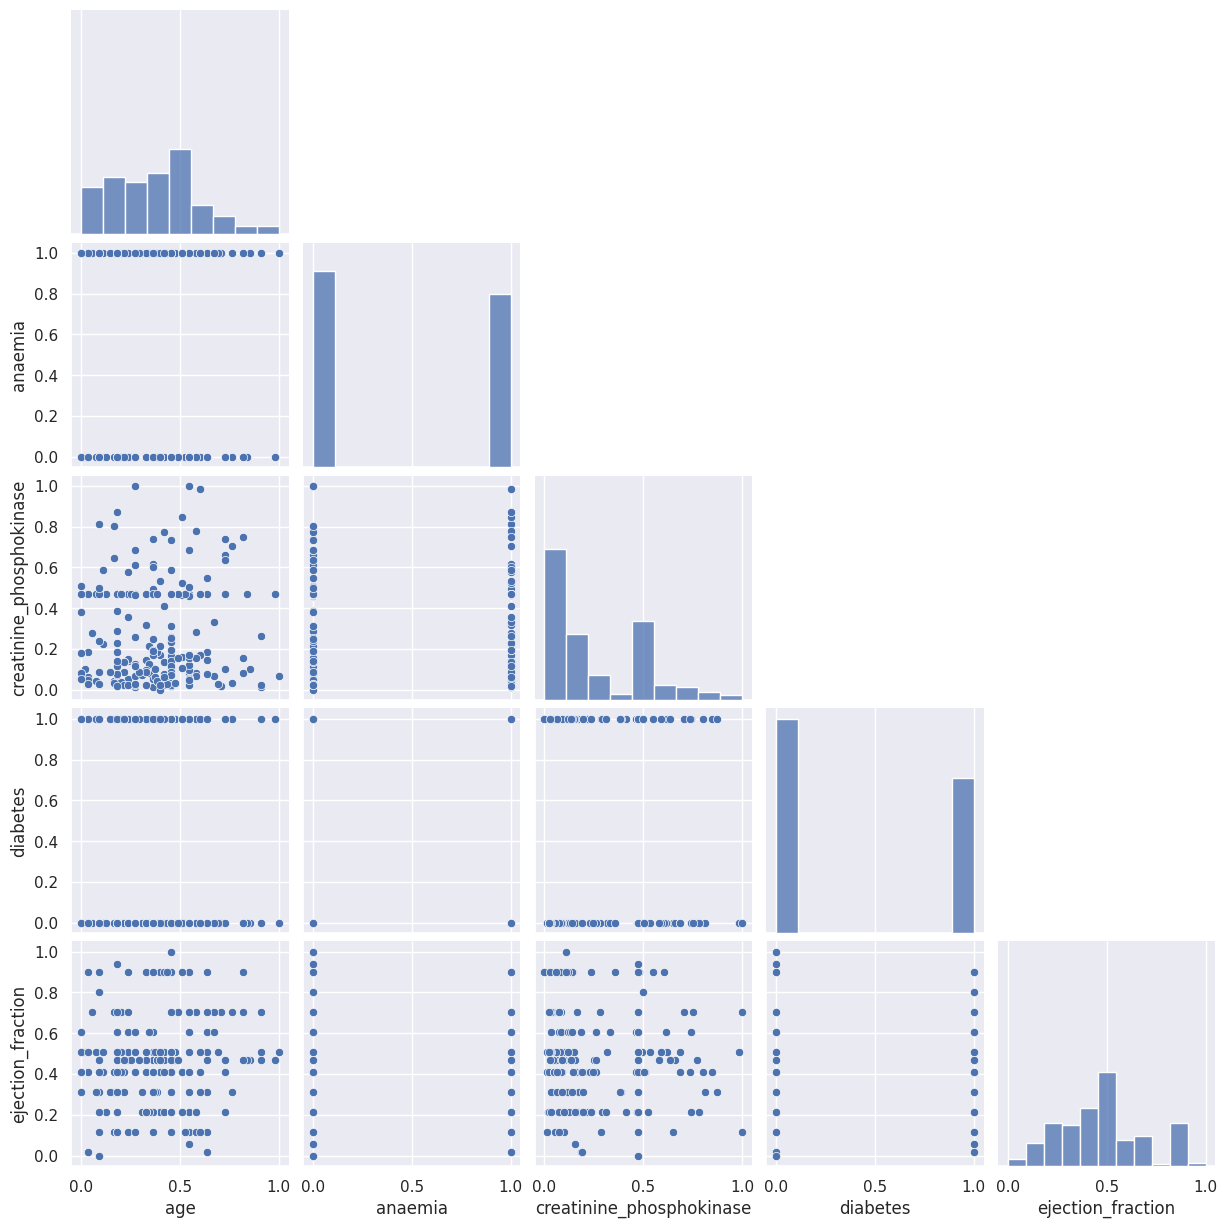


Remaining Missing Values
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
age_group                   0
risk_score                  0
dtype: int64

Cleaned dataset saved as heart_failure_cleaned.csv


In [ ]:
# ==========================================================
# AI in Healthcare - Lab Assignment 2
# Data Cleaning and Enrichment on Heart Failure Dataset
# Google Colab Version
# ==========================================================

# Install libraries (if needed)
# !pip install seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, LabelEncoder

plt.style.use('ggplot')
sns.set(font_scale=1)

# ==========================================================
# 1. Upload Dataset
# ==========================================================

from google.colab import files

uploaded = files.upload()

# Read CSV
df = pd.read_csv(next(iter(uploaded)))

print("Dataset Loaded Successfully!\n")

# ==========================================================
# 2. Display First Five Rows
# ==========================================================

print(df.head())

# ==========================================================
# 3. Dataset Summary
# ==========================================================

print("\nShape:", df.shape)

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

# ==========================================================
# 4. Visualize Missing Values
# (Different visualization)
# ==========================================================

plt.figure(figsize=(10,4))
(df.isnull().sum()).plot(kind='bar', color='teal')
plt.title("Missing Values in Each Column")
plt.ylabel("Count")
plt.show()

# ==========================================================
# 5. Numerical Distributions
# ==========================================================

numerical_cols = df.select_dtypes(include=np.number).columns

for col in numerical_cols:
    plt.figure(figsize=(6,4))
    sns.violinplot(y=df[col], color="skyblue")
    plt.title(f"Distribution of {col}")
    plt.show()

# ==========================================================
# Summary Statistics BEFORE Cleaning
# ==========================================================

print("\nSummary Statistics BEFORE Cleaning")
print(df.describe())

# ==========================================================
# 6. Impute Missing Values
# ==========================================================

for col in df.columns:

    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)

    else:
        df[col].fillna(df[col].median(), inplace=True)

# ==========================================================
# 7. Remove Outliers (IQR Method)
# ==========================================================

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("\nShape after removing outliers:", df.shape)

# ==========================================================
# 8. Correct Inconsistencies
# ==========================================================

if "age" in df.columns:
    df.loc[df["age"] < 0, "age"] = df["age"].median()

# ==========================================================
# 9. Feature Engineering
# ==========================================================

if "age" in df.columns:

    df["age_group"] = pd.cut(
        df["age"],
        bins=[0,40,60,120],
        labels=["Young","Middle","Senior"]
    )

if "ejection_fraction" in df.columns and "serum_creatinine" in df.columns:

    ef = (df["ejection_fraction"] - df["ejection_fraction"].min()) / \
         (df["ejection_fraction"].max() - df["ejection_fraction"].min())

    sc = (df["serum_creatinine"] - df["serum_creatinine"].min()) / \
         (df["serum_creatinine"].max() - df["serum_creatinine"].min())

    df["risk_score"] = ef * sc

# ==========================================================
# 10. Encode Categorical Variables
# ==========================================================

cat_cols = df.select_dtypes(include='object').columns.tolist()

if "age_group" in df.columns:
    cat_cols.append("age_group")

for col in cat_cols:

    encoder = LabelEncoder()

    df[col] = encoder.fit_transform(df[col].astype(str))

# ==========================================================
# 11. Normalize Numerical Features
# ==========================================================

scaler = MinMaxScaler()

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# ==========================================================
# 12. Summary Statistics AFTER Cleaning
# ==========================================================

print("\nSummary Statistics AFTER Cleaning")

print(df.describe())

# ==========================================================
# 13. Validation Plots
# ==========================================================

for col in numerical_cols:

    plt.figure(figsize=(6,4))

    sns.histplot(df[col], bins=20, kde=True, color='purple')

    plt.title(f"Cleaned Distribution of {col}")

    plt.show()

# ==========================================================
# Pairplot (Extra Visualization)
# ==========================================================

sample_cols = numerical_cols[:5]

sns.pairplot(df[sample_cols], corner=True)

plt.show()

# ==========================================================
# 14. Check Missing Values
# ==========================================================

print("\nRemaining Missing Values")

print(df.isnull().sum())

# ==========================================================
# Save Cleaned Dataset
# ==========================================================

df.to_csv("heart_failure_cleaned.csv", index=False)

print("\nCleaned dataset saved as heart_failure_cleaned.csv")